<a href="https://colab.research.google.com/github/Bhuvan152/emg-sensor-selection/blob/main/emg_sensor_selection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
!apt-get -qq install -y p7zip-full > /dev/null

import glob, os
os.makedirs("/content/mats", exist_ok=True)

for z in sorted(glob.glob("/content/*.zip")):
    print("Extracting from", os.path.basename(z))
    !7z e "{z}" "*_E1_A1.mat" -r -o/content/mats -y > /dev/null

print("\nFiles extracted:")
for f in sorted(glob.glob("/content/mats/*.mat")):
    print(f"  {os.path.basename(f)}: {os.path.getsize(f)/1e6:.1f} MB")

Extracting from DB2_s1.zip
Extracting from DB2_s2.zip
Extracting from DB2_s3.zip
Extracting from DB2_s4.zip
Extracting from DB2_s5.zip

Files extracted:
  S1_E1_A1.mat: 151.5 MB
  S2_E1_A1.mat: 172.0 MB
  S3_E1_A1.mat: 152.9 MB
  S4_E1_A1.mat: 166.9 MB
  S5_E1_A1.mat: 162.5 MB


In [7]:
import glob, numpy as np
from scipy.io import loadmat

DATA_DIR = "/content"

def find_file(subj):
    return glob.glob(f"{DATA_DIR}/**/S{subj}_E1_A1.mat", recursive=True)[0]

for s in range(1, 6):
    print("Found:", find_file(s))

d = loadmat(find_file(1))
emg = d["emg"]
print("\nEMG shape:", emg.shape)
print("Movement labels:", np.unique(d["restimulus"]))
print("Repetitions:", np.unique(d["rerepetition"]))
print("Duration (minutes):", round(emg.shape[0] / 2000 / 60, 1))

Found: /content/mats/S1_E1_A1.mat
Found: /content/mats/S2_E1_A1.mat
Found: /content/mats/S3_E1_A1.mat
Found: /content/mats/S4_E1_A1.mat
Found: /content/mats/S5_E1_A1.mat

EMG shape: (1808331, 12)
Movement labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17]
Repetitions: [0 1 2 3 4 5 6]
Duration (minutes): 15.1


In [8]:
WIN, STEP, N_SENSORS = 400, 100, 12
MOVEMENTS = [5, 6, 13, 14]   # spread fingers, fist, wrist flexion, wrist extension
TRAIN_REPS, TEST_REPS = [1, 3, 4, 6], [2, 5]

def load_subject(subj):
    d = loadmat(find_file(subj))
    emg = d["emg"].astype(np.float64)
    labels = d["restimulus"].ravel().astype(int)
    reps = d["rerepetition"].ravel().astype(int)
    idx = np.where(reps > 0, np.arange(len(reps)), 0)
    np.maximum.accumulate(idx, out=idx)
    return emg, labels, reps[idx]

def make_windows(emg, labels, reps, seed=0):
    keep = set([0] + MOVEMENTS)
    X, y, r = [], [], []
    for start in range(0, len(labels) - WIN, STEP):
        end = start + WIN
        lab = labels[start]
        if lab not in keep or reps[start] == 0:
            continue
        if not np.all(labels[start:end] == lab):
            continue
        w = emg[start:end]
        mav = np.mean(np.abs(w), axis=0)
        rms = np.sqrt(np.mean(w ** 2, axis=0))
        X.append(np.log(np.concatenate([mav, rms]) + 1e-8))
        y.append(lab)
        r.append(reps[start])
    X, y, r = np.array(X), np.array(y), np.array(r)
    rng = np.random.default_rng(seed)
    rest = np.where(y == 0)[0]
    target = int(np.mean([np.sum(y == m) for m in MOVEMENTS]))
    drop = rng.choice(rest, size=max(len(rest) - target, 0), replace=False)
    mask = np.ones(len(y), dtype=bool)
    mask[drop] = False
    return X[mask], y[mask], r[mask]

def split(X, y, r):
    tr, te = np.isin(r, TRAIN_REPS), np.isin(r, TEST_REPS)
    return X[tr], y[tr], X[te], y[te]

data = {}
for s in range(1, 6):
    data[s] = split(*make_windows(*load_subject(s)))
    Xtr, ytr, Xte, yte = data[s]
    print(f"Subject {s}: {len(ytr)} train / {len(yte)} test windows, classes = {np.unique(ytr)}")

Subject 1: 1097 train / 556 test windows, classes = [ 0  5  6 13 14]
Subject 2: 1522 train / 755 test windows, classes = [ 0  5  6 13 14]
Subject 3: 1284 train / 642 test windows, classes = [ 0  5  6 13 14]
Subject 4: 1757 train / 698 test windows, classes = [ 0  5  6 13 14]
Subject 5: 938 train / 479 test windows, classes = [ 0  5  6 13 14]


In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

baseline = {}
for s, (Xtr, ytr, Xte, yte) in data.items():
    sc = StandardScaler().fit(Xtr)
    clf = LogisticRegression(max_iter=2000).fit(sc.transform(Xtr), ytr)
    baseline[s] = accuracy_score(yte, clf.predict(sc.transform(Xte)))
    print(f"Subject {s}: accuracy with all 12 sensors = {baseline[s]:.3f}")

Subject 1: accuracy with all 12 sensors = 0.894
Subject 2: accuracy with all 12 sensors = 0.816
Subject 3: accuracy with all 12 sensors = 0.924
Subject 4: accuracy with all 12 sensors = 0.855
Subject 5: accuracy with all 12 sensors = 0.933


In [10]:
import warnings
warnings.filterwarnings("ignore")

def sensors_used(coef):
    w = np.abs(coef[:, :N_SENSORS]) + np.abs(coef[:, N_SENSORS:])
    return np.where(w.sum(axis=0) > 1e-6)[0]

Cs = np.logspace(-3, 1, 25)
results = {}

for s, (Xtr, ytr, Xte, yte) in data.items():
    sc = StandardScaler().fit(Xtr)
    Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)
    best = {}
    for C in Cs:
        l1 = LogisticRegression(penalty="l1", solver="saga", C=C, max_iter=5000).fit(Xtr_s, ytr)
        used = sensors_used(l1.coef_)
        k = len(used)
        if k == 0 or k in best:
            continue
        cols = np.concatenate([used, used + N_SENSORS])
        refit = LogisticRegression(max_iter=2000).fit(Xtr_s[:, cols], ytr)
        best[k] = (accuracy_score(yte, refit.predict(Xte_s[:, cols])), used + 1)
    results[s] = best
    print(f"\nSubject {s}")
    for k in sorted(best):
        print(f"  {k:2d} sensors -> accuracy {best[k][0]:.3f}   kept: {list(best[k][1])}")


Subject 1
   1 sensors -> accuracy 0.531   kept: [np.int64(8)]
   3 sensors -> accuracy 0.752   kept: [np.int64(8), np.int64(9), np.int64(12)]
   4 sensors -> accuracy 0.790   kept: [np.int64(4), np.int64(8), np.int64(9), np.int64(12)]
   6 sensors -> accuracy 0.818   kept: [np.int64(2), np.int64(4), np.int64(8), np.int64(9), np.int64(10), np.int64(12)]
   8 sensors -> accuracy 0.842   kept: [np.int64(2), np.int64(3), np.int64(4), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
   9 sensors -> accuracy 0.858   kept: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
  10 sensors -> accuracy 0.872   kept: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(6), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
  12 sensors -> accuracy 0.894   kept: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int

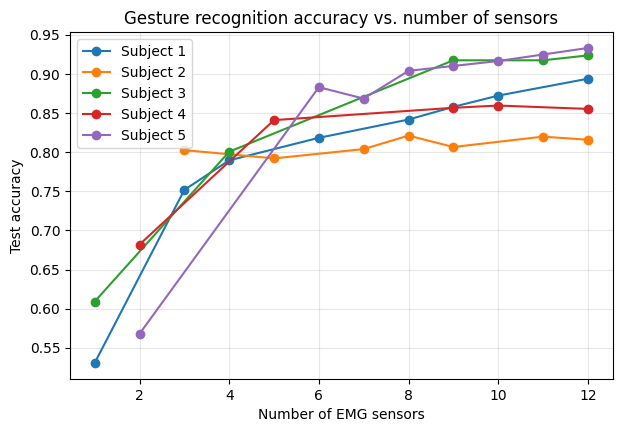

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import matplotlib.pyplot as plt
from google.colab import files

plt.figure(figsize=(7, 4.5))
for s, best in results.items():
    ks = sorted(best)
    plt.plot(ks, [best[k][0] for k in ks], marker="o", label=f"Subject {s}")
plt.xlabel("Number of EMG sensors")
plt.ylabel("Test accuracy")
plt.title("Gesture recognition accuracy vs. number of sensors")
plt.grid(alpha=0.3)
plt.legend()
plt.savefig("accuracy_vs_sensors.png", dpi=200, bbox_inches="tight")
plt.show()

files.download("accuracy_vs_sensors.png")

In [12]:
from collections import Counter

for budget in [2, 3, 4]:
    counts = Counter()
    for s, best in results.items():
        ks = [k for k in best if k <= budget]
        if ks:
            counts.update(best[max(ks)][1].tolist())
    print(f"With up to {budget} sensors, times each sensor was chosen (out of 5 subjects):")
    print("  ", dict(sorted(counts.items(), key=lambda x: -x[1])))

With up to 2 sensors, times each sensor was chosen (out of 5 subjects):
   {8: 2, 10: 1, 2: 1, 11: 1, 4: 1}
With up to 3 sensors, times each sensor was chosen (out of 5 subjects):
   {8: 2, 12: 2, 10: 2, 11: 2, 9: 1, 2: 1, 4: 1}
With up to 4 sensors, times each sensor was chosen (out of 5 subjects):
   {8: 3, 4: 2, 9: 2, 12: 2, 10: 2, 11: 2, 2: 2}
